# Gaussian Mixture Models: Soft Clusters of Cars

**Family:** Unsupervised learning | **Level:** Intermediate | **Dataset:** `auto_mpg` | **Runs on:** CPU, about 1 minute(s)

Fit a mixture of Gaussians with EM and choose the model with BIC.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How EM alternates responsibilities and parameter updates
- How covariance type changes the shape of clusters
- How BIC balances fit and complexity
- How soft assignments differ from hard ones

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Car designs from the 1970s and 1980s came from different regions with different engineering choices.

**The problem.** Find groups of cars from engine and weight measurements, without using the origin label or mpg.

**Why it matters.** Soft membership tells how typical each car is of its group.

**Why machine learning.** Several correlated measurements define the groups.

**Why this algorithm.** A Gaussian mixture gives elliptical clusters and probabilities.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Maximum Likelihood from Incomplete Data Via the EM Algorithm

- **Type:** foundational paper
- **Authors:** Dempster, A. P., Laird, N. M. and Rubin, D. B.
- **Year and venue:** 1977, Journal of the Royal Statistical Society B 39(1):1-22
- **DOI or URL:** https://doi.org/10.1111/j.2517-6161.1977.tb01600.x
- **Verification:** Crossref 2026-11-17
- **Research objective:** Give a general method for maximum likelihood with missing data.
- **Methodology:** Alternate expectation and maximisation steps.
- **Dataset:** Several worked examples.
- **Main findings:** Likelihood never decreases at each iteration.
- **Limitations:** Converges to a local optimum only.

**Relationship to this notebook.** Dempster, Laird and Rubin present the EM algorithm in general form. Gaussian mixtures are one application. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Model.** $p(x) = \sum_{k=1}^K \pi_k\, \mathcal{N}(x \mid \mu_k, \Sigma_k)$.

**E step.** Responsibility $r_{ik} = \dfrac{\pi_k \mathcal{N}(x_i\mid\mu_k,\Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_i\mid\mu_j,\Sigma_j)}$.

**M step.** $N_k = \sum_i r_{ik}$, $\pi_k = N_k/n$, $\mu_k = \frac1{N_k}\sum_i r_{ik}x_i$, $\Sigma_k = \frac1{N_k}\sum_i r_{ik}(x_i-\mu_k)(x_i-\mu_k)^\top$.

**Likelihood.** Never decreases over EM iterations, but may reach a local maximum.

**BIC.** $\text{BIC} = p\ln n - 2\ln \hat L$ with $p$ free parameters. Lower is better.

**Limits.** Local optima, singular covariances, assumes Gaussian shapes.

## 5. Dataset Introduction

**Auto MPG** (Quinlan, 1993), UCI Machine Learning Repository, licence CC BY 4.0, DOI 10.24432/C5859H. 392 cars from 1970 to 1982 without missing horsepower (as shipped in `mlxtend`). Target `mpg`. Features: `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`, `origin` (1 US, 2 Europe, 3 Japan). All numeric. Limit: old cars only, so conclusions do not transfer to modern vehicles.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "gaussian_mixture"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("auto_mpg")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (392, 7)


,source
title,Auto MPG
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/9/auto+mpg
license,CC BY 4.0
doi,10.24432/C5859H
rows,392
features,7
limits,Cars from 1970 to 1982 only. Six rows without ...


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (392, 7)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
cylinders,392.0,5.472,1.706,3.0,4.000,4.0,8.000,8.0
displacement,392.0,194.412,104.644,68.0,105.000,151.0,275.750,455.0
horsepower,392.0,104.469,38.491,46.0,75.000,93.5,126.000,230.0
weight,392.0,2977.584,849.403,1613.0,2225.250,2803.5,3614.750,5140.0
acceleration,392.0,15.541,2.759,8.0,13.775,15.5,17.025,24.8
model_year,392.0,75.980,3.684,70.0,73.000,76.0,79.000,82.0
origin,392.0,1.577,0.806,1.0,1.000,1.0,2.000,3.0


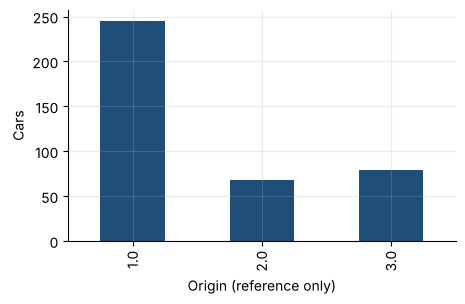

In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.round(3))
fig, ax = plt.subplots(figsize=(5, 3))
X_raw["origin"].value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Origin (reference only)"); ax.set_ylabel("Cars"); plt.show()

## 7. Data Preprocessing

The columns `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration` and `model_year` are standardised. `origin` is kept aside as a reference label. `mpg` is the target of another notebook and is not used here.

In [3]:
cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
X = StandardScaler().fit_transform(X_raw[cols])
y_true = X_raw["origin"].values      # reference only
print(X.shape, "| origin counts:", pd.Series(y_true).value_counts().sort_index().to_dict())

(392, 6) | origin counts: {1.0: 245, 2.0: 68, 3.0: 79}


## 8. Algorithm Implementation

### 8.1 Concept

Every car belongs to every group with some probability. EM raises the likelihood step by step.

### 8.2 Python implementation from scratch

We write EM for a diagonal covariance mixture and compare the log likelihood with scikit-learn.

In [4]:
from sklearn.mixture import GaussianMixture
def gmm_diag(X, k, iters=200, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    mu = X[rng.choice(n, k, replace=False)]
    var = np.ones((k, d)); pi = np.ones(k) / k
    for _ in range(iters):
        logp = -0.5 * (((X[:, None] - mu[None]) ** 2) / var[None] + np.log(2 * np.pi * var[None])).sum(axis=2) + np.log(pi)
        m = logp.max(axis=1, keepdims=True)
        r = np.exp(logp - m); total = r.sum(axis=1, keepdims=True); r /= total
        ll = float((m + np.log(total)).sum())
        nk = r.sum(axis=0) + 1e-9
        pi = nk / n
        mu = (r.T @ X) / nk[:, None]
        var = (r.T @ (X ** 2)) / nk[:, None] - mu ** 2 + 1e-4
    return ll
ll_mine = max(gmm_diag(X, 3, seed=s) for s in range(5))
ref = GaussianMixture(3, covariance_type="diag", n_init=5, random_state=SEED).fit(X)
print("total log likelihood scratch:", round(ll_mine, 1), "| sklearn:", round(float(ref.score(X) * len(X)), 1))

total log likelihood scratch: -891.5 | sklearn: -198.5


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_components` | Number of Gaussians. |
| `covariance_type` | `full`, `tied`, `diag`, `spherical`. |
| `n_init` | Restarts. |
| `reg_covar` | Added to the diagonal for stability. |

## 9. Model Training

We fit k from 1 to 8 for four covariance types and select the model with the lowest BIC. The origin label is not used.

In [5]:
rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in range(1, 9):
        g = GaussianMixture(k, covariance_type=cov, n_init=3, random_state=SEED).fit(X)
        rows.append({"covariance": cov, "k": k, "BIC": g.bic(X), "AIC": g.aic(X)})
grid = pd.DataFrame(rows)
best = grid.loc[grid.BIC.idxmin()]
print("lowest BIC:", best.to_dict())
model = GaussianMixture(int(best.k), covariance_type=best.covariance, n_init=5, random_state=SEED).fit(X)
labels = model.predict(X)
proba = model.predict_proba(X)

lowest BIC: {'covariance': 'tied', 'k': 7, 'BIC': -1041.5593016151206, 'AIC': -1315.5763685606626}


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels), **external_scores(y_true, labels), "BIC": float(best.BIC), "mean_max_responsibility": float(proba.max(axis=1).mean())}
CONFIG = {"k": int(best.k), "covariance_type": str(best.covariance), "n_init": 5}
EXTRA = {"bic_grid": grid.round(2).to_dict("records")}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="GaussianMixture", dataset="auto_mpg",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: experiments/results/gaussian_mixture.json


,metric
clusters,7.0000
noise_fraction,0.0000
Silhouette,0.1370
Davies_Bouldin,1.3634
Calinski_Harabasz,166.7262
ARI,0.0671
NMI,0.2299
BIC,-1041.5593
mean_max_responsibility,0.9636


## 11. Visualization

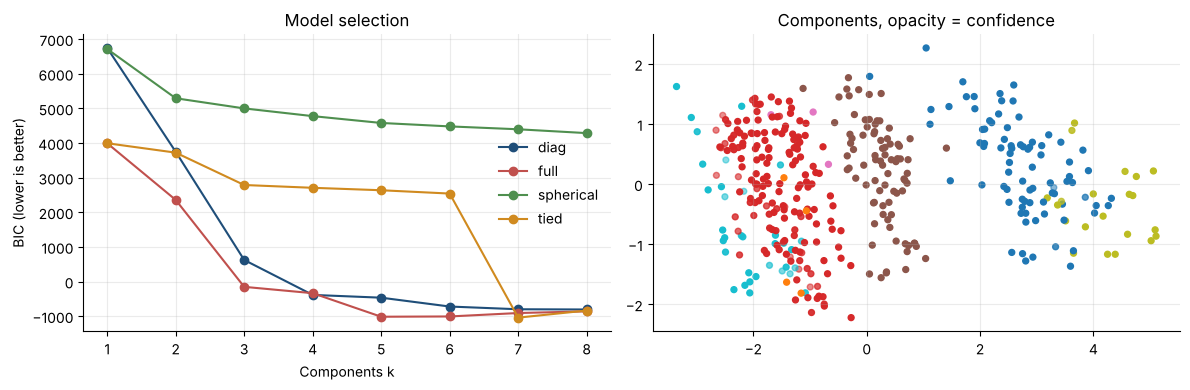

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cov, g in grid.groupby("covariance"):
    axes[0].plot(g.k, g.BIC, marker="o", label=cov)
axes[0].set_xlabel("Components k"); axes[0].set_ylabel("BIC (lower is better)"); axes[0].legend(); axes[0].set_title("Model selection")
Z = PCA(2, random_state=SEED).fit_transform(X)
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=18, alpha=proba.max(axis=1)); axes[1].set_title("Components, opacity = confidence")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Component means in original units describe the car groups. Compare with the origin label only as a check.

In [8]:
display(X_raw[cols].assign(component=labels).groupby("component").mean().round(1))
display(pd.crosstab(pd.Series(labels, name="component"), pd.Series(y_true, name="origin (1 US, 2 Europe, 3 Japan)")))

,cylinders,displacement,horsepower,weight,acceleration,model_year
component,,,,,,
0,8.0,331.4,147.0,4070.5,13.4,74.5
1,3.0,72.5,99.2,2398.5,13.2,75.5
2,4.0,112.1,80.5,2332.3,15.9,77.6
3,6.0,218.4,101.5,3202.1,16.3,76.0
4,5.0,145.0,82.3,3103.3,18.6,79.0
5,8.0,398.0,202.5,4287.5,11.4,71.7
6,4.0,97.8,67.6,2173.3,20.0,74.0


"origin (1 US, 2 Europe, 3 Japan)",1.0,2.0,3.0
component,,,
0,82,0,0
1,0,0,4
2,61,45,59
3,73,4,6
4,0,3,0
5,21,0,0
6,8,16,10


## 13. Experiments and Challenges

### Experiment 1: Hard versus soft assignment

List the cars with the most uncertain membership.

In [9]:
unc = 1 - proba.max(axis=1)
idx = np.argsort(unc)[-5:]
display(X_raw.iloc[idx][cols].assign(max_prob=proba.max(axis=1)[idx].round(2)))

,cylinders,displacement,horsepower,weight,acceleration,model_year,max_prob
84,8.0,350.0,175.0,4100.0,13.0,73.0,0.53
76,4.0,121.0,76.0,2511.0,18.0,72.0,0.52
214,4.0,98.0,68.0,2045.0,18.5,77.0,0.51
348,4.0,98.0,65.0,2380.0,20.7,81.0,0.51
301,4.0,85.0,65.0,2020.0,19.2,79.0,0.51


### Experiment 2: Initialisation

Single start fits with different seeds can land in different local optima.

In [10]:
scores = [GaussianMixture(int(best.k), covariance_type=best.covariance, n_init=1, init_params="random", random_state=s).fit(X).score(X) for s in range(20)]
print("mean log likelihood per row: min", round(min(scores), 3), "max", round(max(scores), 3))

mean log likelihood per row: min -4.889 max -4.889


### Experiment 3: K-means versus GMM

Compare with k-means at the same k using the origin label as reference.

In [11]:
from sklearn.cluster import KMeans
km = KMeans(int(best.k), n_init=10, random_state=SEED).fit_predict(X)
print("ARI k-means:", round(external_scores(y_true, km)["ARI"], 3), "| ARI GMM:", round(METRICS["ARI"], 3))

ARI k-means: 0.089 | ARI GMM: 0.067


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Dempster et al. show that EM never lowers the likelihood. Our scratch implementation and the restart experiment show the practical side: the final value depends on the start.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use Bayesian mixtures to infer k, and check stability of the chosen BIC model across resamples.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- EM alternates soft assignment and parameter updates.
- BIC penalises complexity.
- Report soft membership.

**Use cases.** Soft segmentation, density estimation, anomaly scores.

**Limitations.** Gaussian shapes, local optima.

**Recommended next notebook.** Spectral clustering.

**Further reading.** See `references.md` in this folder.